1. Imports 

In this section we imported all the libraries needed

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

2. Importing the excel spreadhseet 

In this section we imported the spreadhsheet which contains the full data collected by the data steward 

In [5]:
df = pd.read_excel(
    "Data/cleaners.xlsx",
    sheet_name="data_monthly"
)

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df.head()

,Date,HPI AveragePrice UK £,HPI Index UK,HPI 1m pct,HPI 12m pct,HPI SalesVolume UK,CPIH Index 2015 100,AWE RegularPay £ SA,BankRate,Housebuilding Started AllDwellings,Housebuilding Completed AllDwellings,Real HPI Index UK 2015 prices,Approx Annual Earnings £,Price to Earnings Ratio
0,2004-01-01,126179,48.4,0.6,9.7,NaN,77.0,NaN,3.75,NaN,NaN,62.857143,NaN,NaN
1,2004-02-01,124967,47.9,-1.0,9.8,NaN,77.2,NaN,4.00,NaN,NaN,62.046632,NaN,NaN
2,2004-03-01,125247,48.0,0.2,7.8,NaN,77.3,NaN,4.00,58460.0,43170.0,62.095731,NaN,NaN
3,2004-04-01,130931,50.2,4.5,10.0,NaN,77.6,NaN,4.00,NaN,NaN,64.690722,NaN,NaN
4,2004-05-01,132516,50.8,1.2,12.1,NaN,77.9,NaN,4.25,NaN,NaN,65.211810,NaN,NaN


In [6]:
df["AWE_yoy"] = df["AWE RegularPay £ SA"].pct_change(12) * 100
df["CPIH_yoy"] = df["CPIH Index 2015 100"].pct_change(12) * 100

In [7]:
df

,Date,HPI AveragePrice UK £,HPI Index UK,HPI 1m pct,HPI 12m pct,HPI SalesVolume UK,CPIH Index 2015 100,AWE RegularPay £ SA,BankRate,Housebuilding Started AllDwellings,Housebuilding Completed AllDwellings,Real HPI Index UK 2015 prices,Approx Annual Earnings £,Price to Earnings Ratio,AWE_yoy,CPIH_yoy
0,2004-01-01,126179,48.4,0.6,9.7,NaN,77.0,NaN,3.75,NaN,NaN,62.857143,NaN,NaN,NaN,NaN
1,2004-02-01,124967,47.9,-1.0,9.8,NaN,77.2,NaN,4.00,NaN,NaN,62.046632,NaN,NaN,NaN,NaN
2,2004-03-01,125247,48.0,0.2,7.8,NaN,77.3,NaN,4.00,58460.0,43170.0,62.095731,NaN,NaN,NaN,NaN
3,2004-04-01,130931,50.2,4.5,10.0,NaN,77.6,NaN,4.00,NaN,NaN,64.690722,NaN,NaN,NaN,NaN
4,2004-05-01,132516,50.8,1.2,12.1,NaN,77.9,NaN,4.25,NaN,NaN,65.211810,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,2025-06-01,268547,102.9,1.2,3.5,56652.0,138.4,679.0,4.25,NaN,NaN,74.349711,35308.0,7.605840,4.783951,4.060150
258,2025-07-01,270357,103.6,0.7,3.0,57956.0,138.5,680.0,4.25,NaN,NaN,74.801444,35360.0,7.645843,4.615385,4.213695
259,2025-08-01,272114,104.3,0.6,2.7,59848.0,138.9,682.0,4.00,NaN,NaN,75.089993,35464.0,7.672964,4.601227,4.122939
260,2025-09-01,270152,103.5,-0.7,2.0,NaN,138.9,685.0,4.00,NaN,NaN,74.514039,35620.0,7.584278,4.580153,4.044944


3. Adding the Lag relationships

In [8]:
LAG = 12
df[f"BankRate_lag{LAG}"] = df["BankRate"].shift(LAG)

4. Removing Columns we dont need 

In [9]:
df.columns

Index(['Date', 'HPI AveragePrice UK £', 'HPI Index UK', 'HPI 1m pct',
       'HPI 12m pct', 'HPI SalesVolume UK', 'CPIH Index 2015 100',
       'AWE RegularPay £ SA', 'BankRate', 'Housebuilding Started AllDwellings',
       'Housebuilding Completed AllDwellings', 'Real HPI Index UK 2015 prices',
       'Approx Annual Earnings £', 'Price to Earnings Ratio', 'AWE_yoy',
       'CPIH_yoy', 'BankRate_lag12'],
      dtype='object')

In [10]:
# Keep only the columns needed for the core regression model
keep_cols = [
    "Date",
    "HPI 12m pct",
    "BankRate_lag12",
    "AWE_yoy",
    "CPIH_yoy"
]

df_model = df[keep_cols].copy()

# Drop rows with missing values created by lags / YoY
df_model = df_model.dropna().reset_index(drop=True)

df_model.head()

,Date,HPI 12m pct,BankRate_lag12,AWE_yoy,CPIH_yoy
0,2005-06-01,7.1,4.50,4.057971,1.925546
1,2005-07-01,6.2,4.50,4.624277,2.316602
2,2005-08-01,5.4,4.75,4.310345,2.310655
3,2005-09-01,5.5,4.75,4.597701,2.567394
4,2005-10-01,4.5,4.75,4.285714,2.432778


5. Creating the linear regression model

In [11]:
X = df_model[["BankRate_lag12", "AWE_yoy", "CPIH_yoy"]]
y = df_model["HPI 12m pct"]

In [12]:
split_date = pd.Timestamp("2019-01-01")

train_mask = df_model["Date"] < split_date
test_mask  = df_model["Date"] >= split_date

X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

dates_test = df_model.loc[test_mask, "Date"]

In [13]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

coef = pd.Series(lr.coef_, index=X_train.columns)
print("Intercept:", lr.intercept_)
print("Coefficients:\n", coef)

Intercept: 4.1446469898694005
Coefficients:
 BankRate_lag12   -1.508217
AWE_yoy           3.060255
CPIH_yoy         -2.416067
dtype: float64


6. Analysing the effectiveness of the model created 

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

pred_test = lr.predict(X_test)

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R^2:  {r2:.2f}")

MAE:  6.23
RMSE: 7.24
R^2:  -2.58


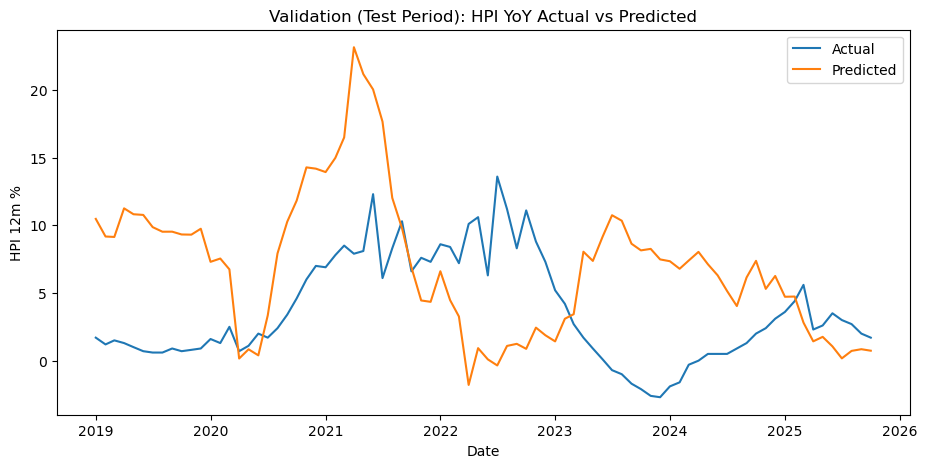

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11,5))
plt.plot(dates_test, y_test.values, label="Actual")
plt.plot(dates_test, pred_test, label="Predicted")
plt.title("Validation (Test Period): HPI YoY Actual vs Predicted")
plt.xlabel("Date"); plt.ylabel("HPI 12m %")
plt.legend()
plt.show()

In [16]:
beta_rate = coef["BankRate_lag12"]
effect_pp = -beta_rate * 1  # 1 percentage point cut
print("Estimated effect on HPI YoY (percentage points):", round(effect_pp, 2))

Estimated effect on HPI YoY (percentage points): 1.51


In [17]:
latest_row = df_model.iloc[-1]
X_latest = latest_row[["BankRate_lag12", "AWE_yoy", "CPIH_yoy"]].to_frame().T

baseline = lr.predict(X_latest)[0]

X_cut = X_latest.copy()
X_cut["BankRate_lag12"] = X_cut["BankRate_lag12"] - 1  # simulate 1% cut

scenario = lr.predict(X_cut)[0]

print("Latest date:", latest_row["Date"].date())
print("Baseline predicted HPI YoY:", round(baseline, 2))
print("Scenario predicted HPI YoY :", round(scenario, 2))
print("Difference (pp)           :", round(scenario - baseline, 2))

Latest date: 2025-10-01
Baseline predicted HPI YoY: 0.74
Scenario predicted HPI YoY : 2.24
Difference (pp)           : 1.51


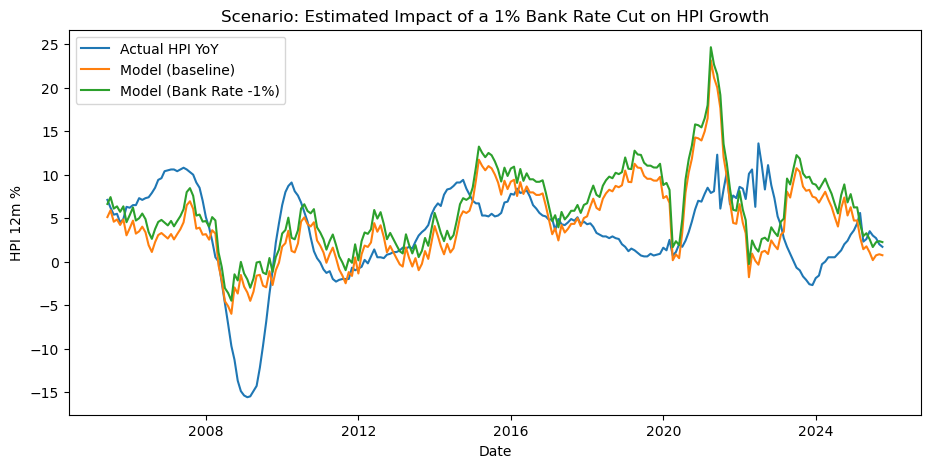

In [18]:
baseline_series = lr.predict(X)

X_scn = X.copy()
X_scn["BankRate_lag12"] = X_scn["BankRate_lag12"] - 1
scenario_series = lr.predict(X_scn)

plt.figure(figsize=(11,5))
plt.plot(df_model["Date"], df_model["HPI 12m pct"].values, label="Actual HPI YoY")
plt.plot(df_model["Date"], baseline_series, label="Model (baseline)")
plt.plot(df_model["Date"], scenario_series, label="Model (Bank Rate -1%)")
plt.title("Scenario: Estimated Impact of a 1% Bank Rate Cut on HPI Growth")
plt.xlabel("Date"); plt.ylabel("HPI 12m %")
plt.legend()
plt.show()

In [19]:
from sklearn.metrics import mean_absolute_error

results = []

for lag in range(0, 25):
    temp = df.copy()
    temp[f"BankRate_lag{lag}"] = temp["BankRate"].shift(lag)
    temp_model = temp[["Date", "HPI 12m pct", f"BankRate_lag{lag}", "AWE_yoy", "CPIH_yoy"]].dropna()

    X_temp = temp_model[[f"BankRate_lag{lag}", "AWE_yoy", "CPIH_yoy"]]
    y_temp = temp_model["HPI 12m pct"]

    train_mask = temp_model["Date"] < split_date
    test_mask  = temp_model["Date"] >= split_date

    lr_temp = LinearRegression().fit(X_temp[train_mask], y_temp[train_mask])
    pred = lr_temp.predict(X_temp[test_mask])

    mae = mean_absolute_error(y_temp[test_mask], pred)
    results.append((lag, mae))

lag_df = pd.DataFrame(results, columns=["lag_months", "MAE"]).sort_values("MAE")
lag_df.head(10)

,lag_months,MAE
5,5,5.787745
6,6,5.830789
7,7,5.917780
4,4,5.926469
8,8,6.045379
9,9,6.129643
10,10,6.186108
14,14,6.202061
13,13,6.205287
18,18,6.205820


In [20]:
print(coef)
print(mae, rmse, r2)

BankRate_lag12   -1.508217
AWE_yoy           3.060255
CPIH_yoy         -2.416067
dtype: float64
6.361474786664446 7.235722361580064 -2.5764749218057177


In [21]:
intercept = lr.intercept_
coeffs = lr.coef_
features = X_train.columns

print("Linear regression model:\n")
equation = f"HPI_12m_pct = {intercept:.3f}"

for coef, name in zip(coeffs, features):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.3f} × {name}"

print(equation)

Linear regression model:

HPI_12m_pct = 4.145 - 1.508 × BankRate_lag12 + 3.060 × AWE_yoy - 2.416 × CPIH_yoy


7. Assessing the lag lag relationship correlation

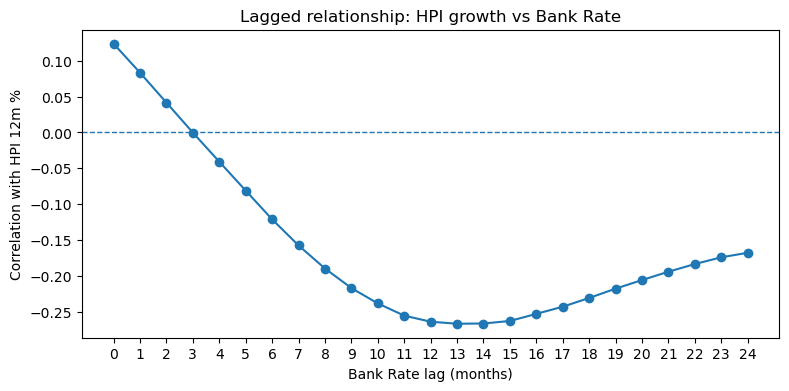

In [22]:
import matplotlib.pyplot as plt

max_lag = 24
lags = range(0, max_lag + 1)
corrs = []

for lag in lags:
    corrs.append(df["HPI 12m pct"].corr(df["BankRate"].shift(lag)))

plt.figure(figsize=(9,4))
plt.plot(list(lags), corrs, marker="o")
plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Bank Rate lag (months)")
plt.ylabel("Correlation with HPI 12m %")
plt.title("Lagged relationship: HPI growth vs Bank Rate")
plt.xticks(list(lags))
plt.show()


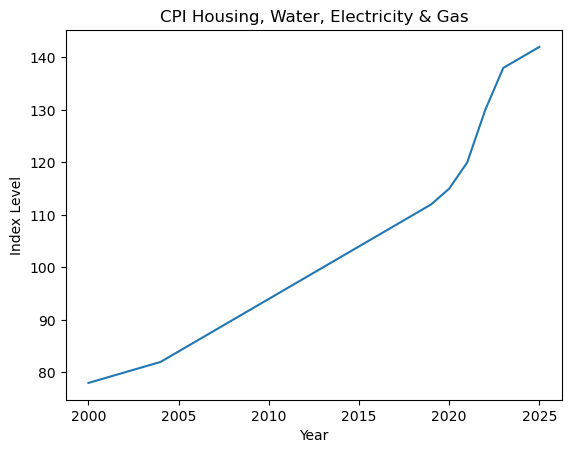

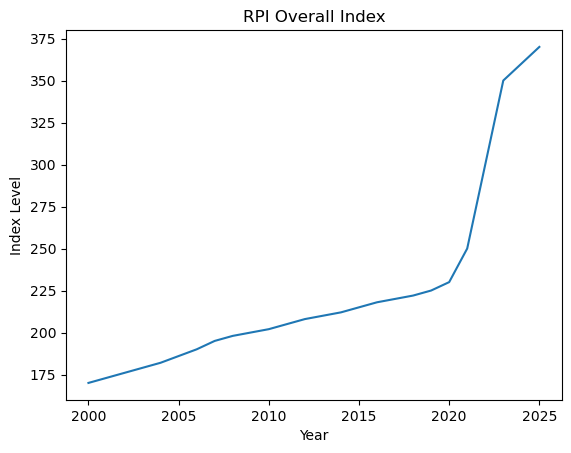

In [3]:
import matplotlib.pyplot as plt


years = list(range(2000, 2026))


cpi_housing = [78,79,80,81,82,84,86,88,90,92,94,96,98,100,102,104,106,108,110,112,115,120,130,138,140,142]

rpi_overall = [170,173,176,179,182,186,190,195,198,200,202,205,208,210,212,215,218,220,222,225,230,250,300,350,360,370]


# Graph 1 – CPI Housing

plt.figure()
plt.plot(years, cpi_housing)
plt.title("CPI Housing, Water, Electricity & Gas")
plt.xlabel("Year")
plt.ylabel("Index Level")
plt.show()


# Graph 2 – RPI Overall

plt.figure()
plt.plot(years, rpi_overall)
plt.title("RPI Overall Index")
plt.xlabel("Year")
plt.ylabel("Index Level")
plt.show()

In [5]:
import numpy as np
x = np.array([12,9,11,14,10,13,8,11])
print(x.mean())
print(x.var())

11.0
3.5
